<a href="https://colab.research.google.com/github/gflamiano/SJU-CSC-672-ML/blob/main/HW7/wine_clustering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Assignment 7

#### Task 1: Print dataset dimensions, feature summary statistics, and missing value checks. Standardize all 13 features and display a comparison of feature distributions before and after scaling.



This cell loads the Wine dataset, checks its basic properties, and standardizes the features.

1. **Load the data.** `load_wine(as_frame=True)` loads the Wine Recognition dataset from scikit-learn. `X` holds the 13 feature columns as a Pandas DataFrame.

2. **Print the dimensions.** `X.shape` gives the number of rows (samples) and columns (features).

3. **Print summary statistics.** `X.describe()` shows the count, mean, standard deviation, minimum, quartiles, and maximum of each feature.

4. **Check for missing values.** `X.isnull().sum()` counts the missing values in each column, and the total is printed below it.

5. **Standardize the features.** `StandardScaler` subtracts each feature's mean and divides by its standard deviation, so every feature ends up with a mean of 0 and a standard deviation of 1. The result is stored as a new DataFrame, `X_scaled`.

6. **Compare the distributions.** Two box plots are drawn side by side, one for the original features and one for the standardized features. Before scaling, the features have very different ranges. For example, `proline` runs from 278 to 1680 and `magnesium` from 70 to 162, while `hue` stays between 0.48 and 1.71 and `nonflavanoid_phenols` between 0.13 and 0.66. This makes the box plot dominated by a few features. After scaling, all 13 features are on the same scale and can be compared directly.

Dataset dimensions: (178, 13)
Number of samples:  178
Number of features: 13

Feature summary statistics:


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
count,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000
mean,13.000618,2.336348,2.366517,19.494944,99.741573,2.295112,2.029270,0.361854,1.590899,5.058090,0.957449,2.611685,746.893258
std,0.811827,1.117146,0.274344,3.339564,14.282484,0.625851,0.998859,0.124453,0.572359,2.318286,0.228572,0.709990,314.907474
min,11.030000,0.740000,1.360000,10.600000,70.000000,0.980000,0.340000,0.130000,0.410000,1.280000,0.480000,1.270000,278.000000
25%,12.362500,1.602500,2.210000,17.200000,88.000000,1.742500,1.205000,0.270000,1.250000,3.220000,0.782500,1.937500,500.500000
50%,13.050000,1.865000,2.360000,19.500000,98.000000,2.355000,2.135000,0.340000,1.555000,4.690000,0.965000,2.780000,673.500000
75%,13.677500,3.082500,2.557500,21.500000,107.000000,2.800000,2.875000,0.437500,1.950000,6.200000,1.120000,3.170000,985.000000
max,14.830000,5.800000,3.230000,30.000000,162.000000,3.880000,5.080000,0.660000,3.580000,13.000000,1.710000,4.000000,1680.000000



Missing values per feature:
alcohol                         0
malic_acid                      0
ash                             0
alcalinity_of_ash               0
magnesium                       0
total_phenols                   0
flavanoids                      0
nonflavanoid_phenols            0
proanthocyanins                 0
color_intensity                 0
hue                             0
od280/od315_of_diluted_wines    0
proline                         0
dtype: int64

Total missing values: 0


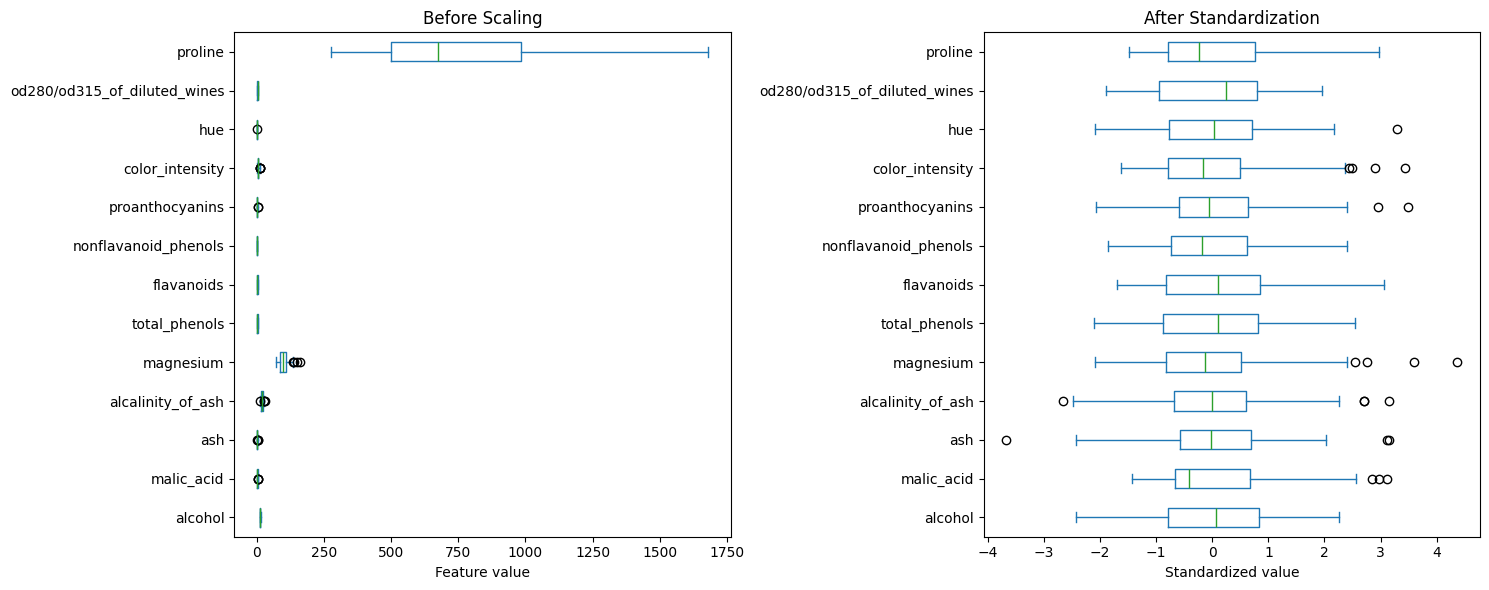

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler

wine = load_wine(as_frame=True)
X = wine.data

print("Dataset dimensions:", X.shape)
print("Number of samples: ", X.shape[0])
print("Number of features:", X.shape[1])

print("\nFeature summary statistics:")
display(X.describe())

print("\nMissing values per feature:")
print(X.isnull().sum())
print("\nTotal missing values:", X.isnull().sum().sum())

scaler = StandardScaler()
X_scaled = pd.DataFrame(scaler.fit_transform(X), columns=X.columns)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

X.plot.box(ax=axes[0], vert=False)
axes[0].set_title("Before Scaling")
axes[0].set_xlabel("Feature value")

X_scaled.plot.box(ax=axes[1], vert=False)
axes[1].set_title("After Standardization")
axes[1].set_xlabel("Standardized value")

plt.tight_layout()
plt.show()

#### Task 2: Iterate k from 1 to 10 for K-Means clustering on the scaled features. Compute and plot side-by-side:

1. The Elbow Method curve.
2. The Silhouette Scores curve for k in [2, 10]. Print the optimal k value suggested by both metrics.

This cell runs K-Means on the scaled features from Task 1 for different numbers of clusters, and uses two metrics to suggest the best number of clusters (k).

1. **Run K-Means for each k.** For k from 1 to 10, a K-Means model is fitted on `X_scaled`. `random_state=42` makes the results repeatable, and `n_init=10` runs each model with 10 different starting points and keeps the best one.

2. **Compute the elbow curve.** For each k, the code records the model's inertia, which is the sum of squared distances from each sample to its nearest cluster center. Inertia always goes down as k grows, but the improvement slows down at some point. The "elbow" is where the curve bends and adding more clusters stops helping much. To pick the elbow automatically, the code finds the point that is farthest from the straight line joining the first and last points of the curve.

3. **Compute the silhouette scores.** For k from 2 to 10, the code calculates the silhouette score, which measures how close each sample is to its own cluster compared with the nearest other cluster. It ranges from -1 to 1, and higher is better. It cannot be computed for k = 1, since there must be at least 2 clusters. The best k is the one with the highest score.

4. **Plot both curves side by side.** The left plot shows inertia against k, and the right plot shows the silhouette score against k.

5. **Print the optimal k.** The code prints the k suggested by the elbow method and the k suggested by the silhouette score.

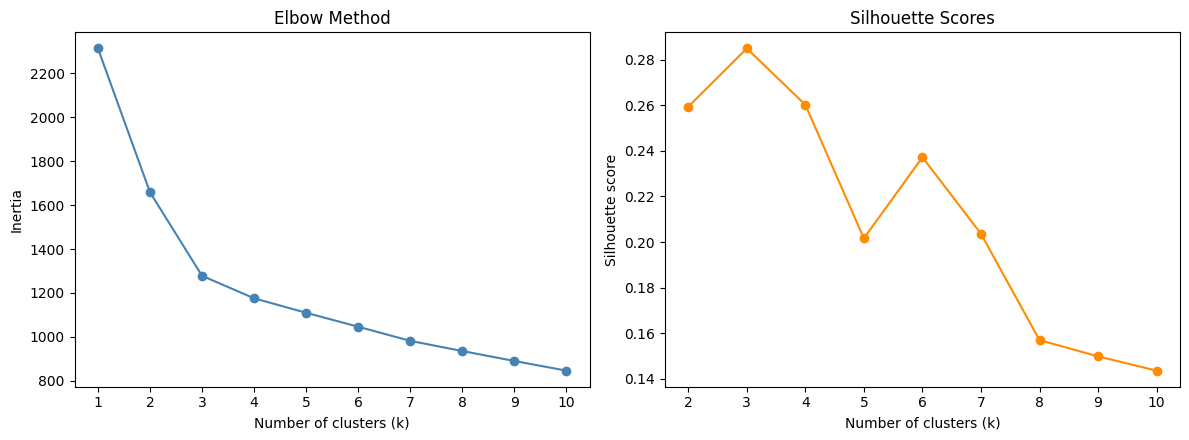

Optimal k suggested by the elbow method:     3
Optimal k suggested by the silhouette score: 3


In [2]:
import numpy as np
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

k_values = list(range(1, 11))
inertias = []
silhouette_scores = {}

for k in k_values:
    kmeans = KMeans(n_clusters=k, n_init=10, random_state=42)
    labels = kmeans.fit_predict(X_scaled)
    inertias.append(kmeans.inertia_)
    if k >= 2:
        silhouette_scores[k] = silhouette_score(X_scaled, labels)

# Elbow Method
inertias = np.array(inertias)
x_norm = (np.array(k_values) - 1) / (len(k_values) - 1)
y_norm = (inertias - inertias[-1]) / (inertias[0] - inertias[-1])
elbow_k = k_values[np.argmax(np.abs(x_norm + y_norm - 1))]

# Silhouette Score
silhouette_k = max(silhouette_scores, key=silhouette_scores.get)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].plot(k_values, inertias, marker="o", color="steelblue")
axes[0].set_xlabel("Number of clusters (k)")
axes[0].set_ylabel("Inertia")
axes[0].set_title("Elbow Method")
axes[0].set_xticks(k_values)

axes[1].plot(list(silhouette_scores.keys()), list(silhouette_scores.values()),
             marker="o", color="darkorange")
axes[1].set_xlabel("Number of clusters (k)")
axes[1].set_ylabel("Silhouette score")
axes[1].set_title("Silhouette Scores")
axes[1].set_xticks(range(2, 11))

plt.tight_layout()
plt.show()

print(f"Optimal k suggested by the elbow method:     {elbow_k}")
print(f"Optimal k suggested by the silhouette score: {silhouette_k}")

#### Task 3: Apply PCA strictly to reduce the 13 scaled features down to 2 principal components for visualization purposes. Fit a K-Means model (k=3) on the 2D projected space. Plot the decision boundaries using the Voronoi method.

This cell reduces the scaled features to 2 dimensions, clusters them with K-Means, and draws the decision boundaries.

1. **Reduce to 2 principal components.** `PCA(n_components=2)` is fitted on the 13 scaled features (`X_scaled` from Task 1) and projects every sample onto the 2 directions that capture the most variance. The result, `X_pca`, has 2 columns and is used only for visualization.

2. **Fit K-Means with k=3.** A K-Means model with 3 clusters is fitted on the 2D projected data. It gives each sample a cluster label and finds the 3 cluster centers (centroids).

3. **Compute the Voronoi diagram.** `Voronoi` takes the 3 centroids and divides the plane into 3 regions. Every point inside a region is closer to that region's centroid than to either of the others. This is exactly how K-Means assigns points to clusters, so the Voronoi lines are the decision boundaries of the model.

4. **Plot the result.** `voronoi_plot_2d` draws the boundary lines. The samples are plotted on top, colored by their cluster label, and the centroids are marked with red X symbols.

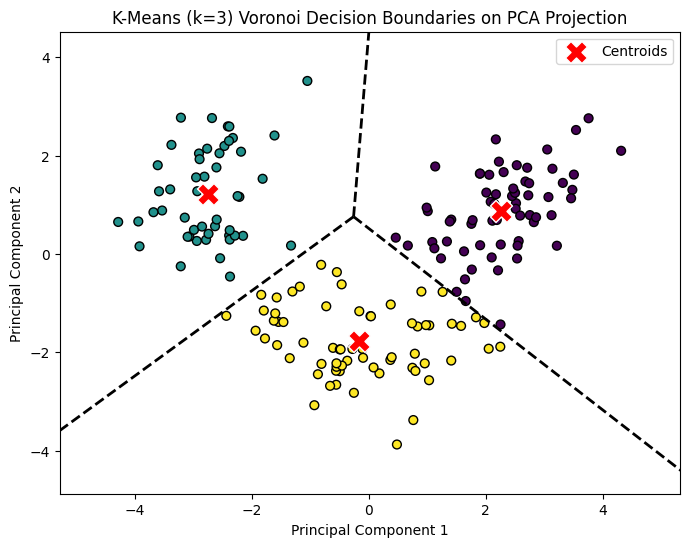

In [3]:
from sklearn.decomposition import PCA
from scipy.spatial import Voronoi, voronoi_plot_2d

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

kmeans_2d = KMeans(n_clusters=3, n_init=10, random_state=42)
labels_2d = kmeans_2d.fit_predict(X_pca)
centers = kmeans_2d.cluster_centers_

vor = Voronoi(centers)

fig, ax = plt.subplots(figsize=(8, 6))

voronoi_plot_2d(vor, ax=ax, show_points=False, show_vertices=False,
                line_colors="black", line_width=2)

ax.scatter(X_pca[:, 0], X_pca[:, 1], c=labels_2d, cmap="viridis",
           edgecolor="k", s=40)
ax.scatter(centers[:, 0], centers[:, 1], marker="X", s=250, c="red",
           edgecolor="white", label="Centroids")

ax.set_xlim(X_pca[:, 0].min() - 1, X_pca[:, 0].max() + 1)
ax.set_ylim(X_pca[:, 1].min() - 1, X_pca[:, 1].max() + 1)

ax.set_xlabel("Principal Component 1")
ax.set_ylabel("Principal Component 2")
ax.set_title("K-Means (k=3) Voronoi Decision Boundaries on PCA Projection")
ax.legend()
plt.show()

#### Task 4: Select 5 representative wine samples from the dataset. Using the fitted 13-feature K-Means model (k=3), compute the distance matrix. Generate and display a heatmap visualizing the soft clustering distance profiles across all 3 cluster centroids, highlighting the minimum distance corresponding to each sample's hard cluster assignment.

This cell fits a K-Means model with k=3 on all 13 scaled features, picks 5 wine samples, and shows how far each one is from every cluster centroid.

1. **Fit the 13-feature K-Means model.** A K-Means model with 3 clusters is fitted on `X_scaled` (all 13 features, not the 2D projection from Task 3). `hard_labels` holds the cluster each sample is assigned to, and `kmeans_13.transform(X_scaled)` gives the distance from every sample to each of the 3 centroids.

2. **Select 5 representative samples.** The first 3 are the samples closest to each centroid, one per cluster, so they are typical members of their clusters. The other 2 are the samples whose distances to their two nearest centroids are the most similar, so they sit near a boundary between clusters.

3. **Build the distance matrix.** The distances of the 5 samples to the 3 centroids are collected into a table with 5 rows and 3 columns and printed.

4. **Draw the heatmap.** Each cell shows the distance from one sample to one centroid, with darker colors meaning larger distances. Because the whole row is shown, it acts as a soft clustering profile: it shows how close the sample is to every cluster, not just the nearest one. The minimum distance in each row, which corresponds to the sample's hard cluster assignment, is highlighted with a red box.

Distance matrix (5 samples x 3 centroids):


,Centroid 0,Centroid 1,Centroid 2
Sample 106 (cluster 0),1.55,4.27,4.30
Sample 148 (cluster 1),4.49,1.08,5.30
Sample 48 (cluster 2),3.81,4.87,1.34
Sample 61 (cluster 1),3.52,3.40,5.25
Sample 121 (cluster 2),6.33,7.48,6.16


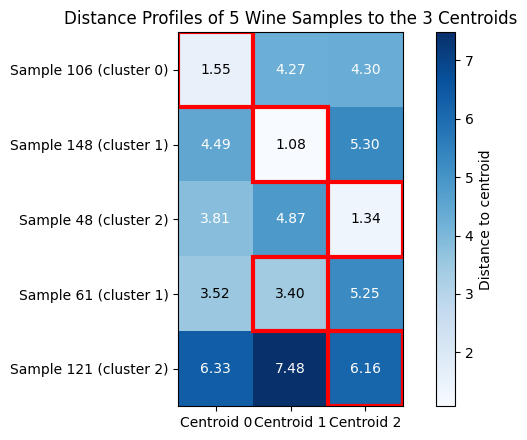

In [4]:
kmeans_13 = KMeans(n_clusters=3, n_init=10, random_state=42)
hard_labels = kmeans_13.fit_predict(X_scaled)

all_dist = kmeans_13.transform(X_scaled)

closest = [int(np.argmin(np.where(hard_labels == c, all_dist[:, c], np.inf))) for c in range(3)]

sorted_dist = np.sort(all_dist, axis=1)
gap = sorted_dist[:, 1] - sorted_dist[:, 0]
boundary = [int(i) for i in np.argsort(gap) if i not in closest][:2]

sample_idx = closest + boundary

row_labels = [f"Sample {i} (cluster {hard_labels[i]})" for i in sample_idx]
col_labels = [f"Centroid {c}" for c in range(3)]
dist_matrix = pd.DataFrame(all_dist[sample_idx], index=row_labels, columns=col_labels)

print("Distance matrix (5 samples x 3 centroids):")
display(dist_matrix.round(2))

fig, ax = plt.subplots(figsize=(7, 4.5))
im = ax.imshow(dist_matrix.values, cmap="Blues")

ax.set_xticks(range(3))
ax.set_xticklabels(col_labels)
ax.set_yticks(range(5))
ax.set_yticklabels(row_labels)

midpoint = dist_matrix.values.max() / 2
for r in range(5):
    for c in range(3):
        value = dist_matrix.values[r, c]
        ax.text(c, r, f"{value:.2f}", ha="center", va="center",
                color="white" if value > midpoint else "black")

for r in range(5):
    c = dist_matrix.values[r].argmin()
    ax.add_patch(plt.Rectangle((c - 0.5, r - 0.5), 1, 1, fill=False,
                               edgecolor="red", linewidth=3))

fig.colorbar(im, ax=ax, label="Distance to centroid")
ax.set_title("Distance Profiles of 5 Wine Samples to the 3 Centroids")
plt.tight_layout()
plt.show()

#### Task 5: Fit a DBSCAN model on the 13-dimensional scaled feature space. Experiment with the two needed hyperparameter settings. Print the number of identified clusters and noise points. Visualize the DBSCAN assignments on the 2D PCA projection space, clearly distinguishing noise points from core cluster members.

This cell tests different DBSCAN settings on the scaled features, then plots one chosen result on the 2D PCA projection.

1. **Explain the two hyperparameters.** `eps` is the maximum distance between two samples for them to count as neighbors. `min_samples` is the number of neighbors a sample needs to be a core point of a cluster. Samples that do not belong to any cluster are labeled as noise (-1).

2. **Experiment with the settings.** DBSCAN is fitted on `X_scaled` (all 13 features) for every combination of five `eps` values (1.5 to 3.5) and three `min_samples` values (3, 5, and 10). For each combination, the code counts the number of clusters found and the number of noise points, and shows the results in a table. The table shows a clear pattern: a small `eps` labels most samples as noise (at `eps=1.5` with `min_samples=5`, all 178 samples are noise), while a larger `eps` merges almost everything into one cluster. No setting found exactly 3 clusters.

3. **Fit the chosen model.** The chosen setting is `eps=2.5` and `min_samples=5`. It finds 1 cluster and 24 noise points (about 13% of the samples), which is a middle point between labeling most samples as noise and labeling very few. The code prints the number of clusters and the number of noise points.

4. **Plot on the PCA projection.** The 2D projection `X_pca` from Task 3 is used only to draw the points, since the clustering itself was done in 13 dimensions. Cluster members are drawn as colored circles, and noise points are drawn as black X symbols so they stand out.

DBSCAN results for different hyperparameter settings:


,eps,min_samples,Clusters,Noise points
0,1.5,3,8,147
1,1.5,5,0,178
2,1.5,10,0,178
3,2.0,3,5,64
4,2.0,5,5,85
5,2.0,10,1,139
6,2.5,3,1,23
7,2.5,5,1,24
8,2.5,10,2,32
9,3.0,3,2,7



Chosen setting: eps=2.5, min_samples=5
Number of clusters identified: 1
Number of noise points:        24


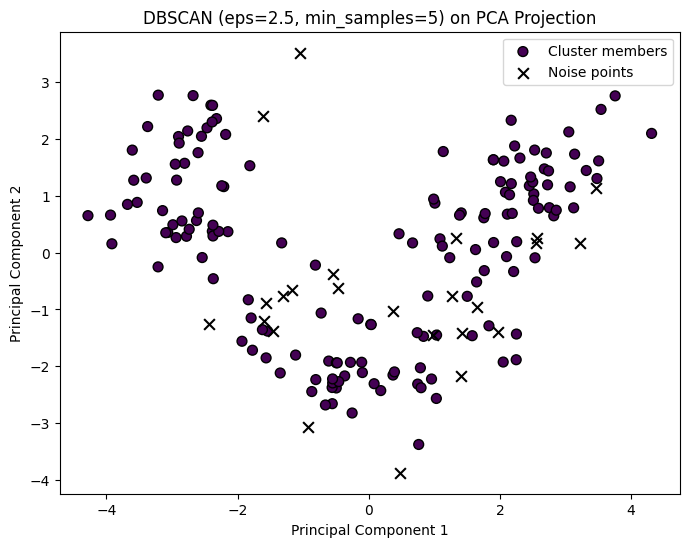

In [5]:
from sklearn.cluster import DBSCAN

eps_values = [1.5, 2.0, 2.5, 3.0, 3.5]
min_samples_values = [3, 5, 10]

results = []
for eps in eps_values:
    for min_samples in min_samples_values:
        db_labels = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(X_scaled)
        n_clusters = len(set(db_labels)) - (1 if -1 in db_labels else 0)
        n_noise = int((db_labels == -1).sum())
        results.append({"eps": eps, "min_samples": min_samples,
                        "Clusters": n_clusters, "Noise points": n_noise})

print("DBSCAN results for different hyperparameter settings:")
display(pd.DataFrame(results))

chosen_eps = 2.5
chosen_min_samples = 5

dbscan = DBSCAN(eps=chosen_eps, min_samples=chosen_min_samples)
db_labels = dbscan.fit_predict(X_scaled)

n_clusters = len(set(db_labels)) - (1 if -1 in db_labels else 0)
n_noise = int((db_labels == -1).sum())

print(f"\nChosen setting: eps={chosen_eps}, min_samples={chosen_min_samples}")
print(f"Number of clusters identified: {n_clusters}")
print(f"Number of noise points:        {n_noise}")

fig, ax = plt.subplots(figsize=(8, 6))

noise_mask = db_labels == -1

ax.scatter(X_pca[~noise_mask, 0], X_pca[~noise_mask, 1], c=db_labels[~noise_mask],
           cmap="viridis", edgecolor="k", s=50, label="Cluster members")
ax.scatter(X_pca[noise_mask, 0], X_pca[noise_mask, 1], c="black", marker="x",
           s=60, label="Noise points")

ax.set_xlabel("Principal Component 1")
ax.set_ylabel("Principal Component 2")
ax.set_title(f"DBSCAN (eps={chosen_eps}, min_samples={chosen_min_samples}) on PCA Projection")
ax.legend()
plt.show()

#### Task 6: Fit an HDBSCAN model (using min_cluster_size=5 or min_samples=5) on the 13-dimensional scaled feature space. Print the total number of clusters discovered and noise points detected. Visualize the resulting HDBSCAN cluster assignments on the 2D PCA projection space.

This cell fits an HDBSCAN model on the scaled features and plots the result on the 2D PCA projection.

1. **Fit HDBSCAN.** HDBSCAN is a density-based clustering method like DBSCAN, but it does not need a fixed `eps` distance. It looks for clusters at many density levels and keeps the most stable ones, so it can find clusters of different densities. The model is fitted on `X_scaled` (all 13 features) with `min_cluster_size=5`, which means a group needs at least 5 samples to count as a cluster. When `min_samples` is not given, it uses the same value as `min_cluster_size`.

2. **Count the clusters and noise points.** The fitted model gives each sample a label. Samples that do not belong to any cluster are labeled -1 (noise). The code prints the number of clusters (the number of distinct labels, not counting -1) and the number of noise points.

3. **Plot on the PCA projection.** The 2D projection `X_pca` from Task 3 is used only to draw the points, since the clustering itself was done in 13 dimensions. Cluster members are drawn as colored circles, one color per cluster, and noise points are drawn as black X symbols so they stand out.

Number of clusters discovered: 2
Number of noise points:        58


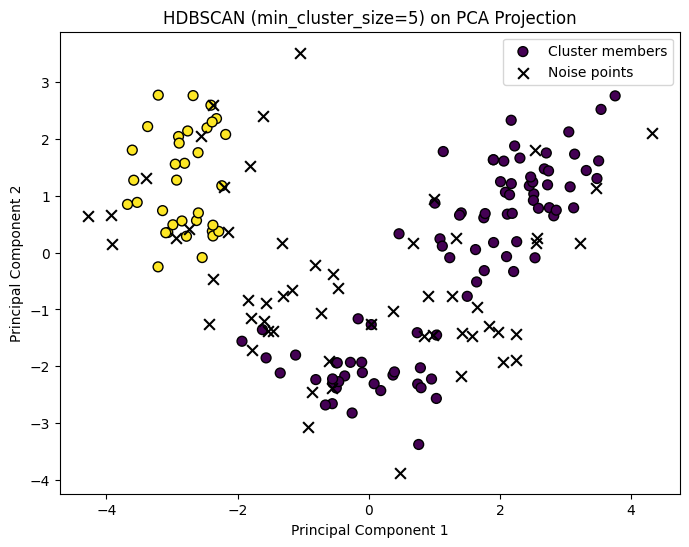

In [6]:
from sklearn.cluster import HDBSCAN

hdbscan = HDBSCAN(min_cluster_size=5)
hdb_labels = hdbscan.fit_predict(X_scaled)

n_clusters = len(set(hdb_labels)) - (1 if -1 in hdb_labels else 0)
n_noise = int((hdb_labels == -1).sum())

print(f"Number of clusters discovered: {n_clusters}")
print(f"Number of noise points:        {n_noise}")

fig, ax = plt.subplots(figsize=(8, 6))

noise_mask = hdb_labels == -1

ax.scatter(X_pca[~noise_mask, 0], X_pca[~noise_mask, 1], c=hdb_labels[~noise_mask],
           cmap="viridis", edgecolor="k", s=50, label="Cluster members")
ax.scatter(X_pca[noise_mask, 0], X_pca[noise_mask, 1], c="black", marker="x",
           s=60, label="Noise points")

ax.set_xlabel("Principal Component 1")
ax.set_ylabel("Principal Component 2")
ax.set_title("HDBSCAN (min_cluster_size=5) on PCA Projection")
ax.legend()
plt.show()

#### Task 7: Compute a single-linkage hierarchical clustering matrix on the scaled Wine features. Plot a hierarchical clustering dendrogram to visualize how individual chemical profiles merge across distance thresholds, connecting the visual structure to HDBSCAN's stability extraction mechanics.

This cell builds a single-linkage hierarchy on the scaled features and draws it as a dendrogram.

1. **Compute the linkage matrix.** `linkage(X_scaled, method="single")` starts with every wine sample as its own cluster and repeatedly merges the two closest clusters. In single linkage, the distance between two clusters is the distance between their two closest samples. Each row of the matrix records one merge: the two clusters joined, the distance at which they joined, and the size of the new cluster. The matrix has 177 rows, one for each merge of the 178 samples.

2. **Plot the dendrogram.** `dendrogram` draws the merges as a tree. The bottom shows the individual wine samples, and the height at which two branches join is the distance at which they merge. Cutting the tree with a horizontal line at some height gives the clusters that exist at that distance.

**Connection to HDBSCAN:**

HDBSCAN uses a tree like this one. It looks at how long each branch stays separate before it merges, and keeps the branches that last the longest and hold enough samples (at least `min_cluster_size`) as clusters. This is called stability. Samples that only join the tree late are labeled noise.

In our dendrogram, most samples merge gradually into one large group, with no big gap that splits it into three clear branches. A small number of samples on the far left, roughly a dozen, join late, at heights between about 2.8 and 4.0. This is why HDBSCAN found only 2 clusters and labeled 58 samples as noise.

Linkage matrix shape: (177, 4)


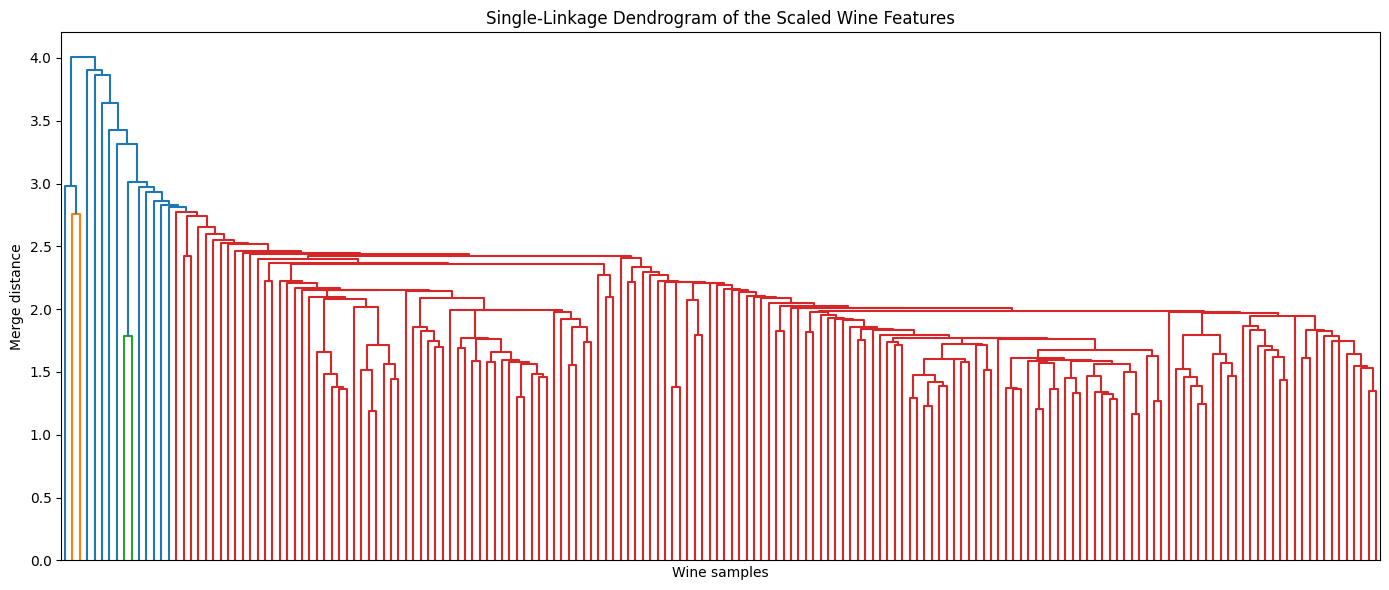

In [7]:
from scipy.cluster.hierarchy import linkage, dendrogram

Z = linkage(X_scaled, method="single")
print("Linkage matrix shape:", Z.shape)

fig, ax = plt.subplots(figsize=(14, 6))
dendrogram(Z, no_labels=True, ax=ax)
ax.set_xlabel("Wine samples")
ax.set_ylabel("Merge distance")
ax.set_title("Single-Linkage Dendrogram of the Scaled Wine Features")
plt.tight_layout()
plt.show()

#### Task 8: Treat the cluster assignments generated by K-Means (k=3), DBSCAN, and HDBSCAN as categorical feature representations or pseudo-labels. Perform a stratified train/test split (80/20) on the Wine dataset and conduct an experiment: train a supervised classifier such as a Random Forest or Logistic Regression using these cluster labels to predict the actual ground-truth wine cultivars (Class 0, 1, 2). Plot the classification accuracy and Silhouette Scores for all three algorithms.

This cell tests how well the cluster assignments from K-Means (k=3), DBSCAN, and HDBSCAN can predict the true wine cultivars (Class 0, 1, 2), and compares that with each algorithm's Silhouette Score.

1. **Collect the cluster labels.** The assignments from the earlier tasks are gathered: `hard_labels` (K-Means), `db_labels` (DBSCAN), and `hdb_labels` (HDBSCAN). The cluster numbers are only names, not quantities, so they are treated as categories.

2. **Split the data.** The 178 samples are split 80/20 with `stratify=y`, so each cultivar appears in the same proportion in the training and test sets. All three algorithms use the same train and test rows, which makes the comparison fair.

3. **Train a classifier on the cluster labels.** For each algorithm, the cluster label is converted into one-hot columns (one column per cluster) with `OneHotEncoder`. Noise points (label -1) get their own column, so they count as a category. A Logistic Regression model is trained on the training rows to predict the true cultivar, and its accuracy is measured on the test rows. A high accuracy means the clusters line up well with the real cultivars.

4. **Compute the Silhouette Score.** For each algorithm, the Silhouette Score is calculated on the 13 scaled features. It measures how well separated the clusters are, from -1 to 1, where higher is better. Noise points are left out of this calculation, and if an algorithm found fewer than 2 clusters, the score cannot be computed and is shown as N/A. This happens for DBSCAN, which found only 1 cluster.

5. **Plot the results.** Two bar charts are drawn side by side, one for the test accuracy and one for the Silhouette Score of each algorithm.

Results:


,Test accuracy,Silhouette score
K-Means (k=3),0.972,0.285
DBSCAN,0.389,NaN
HDBSCAN,0.750,0.352


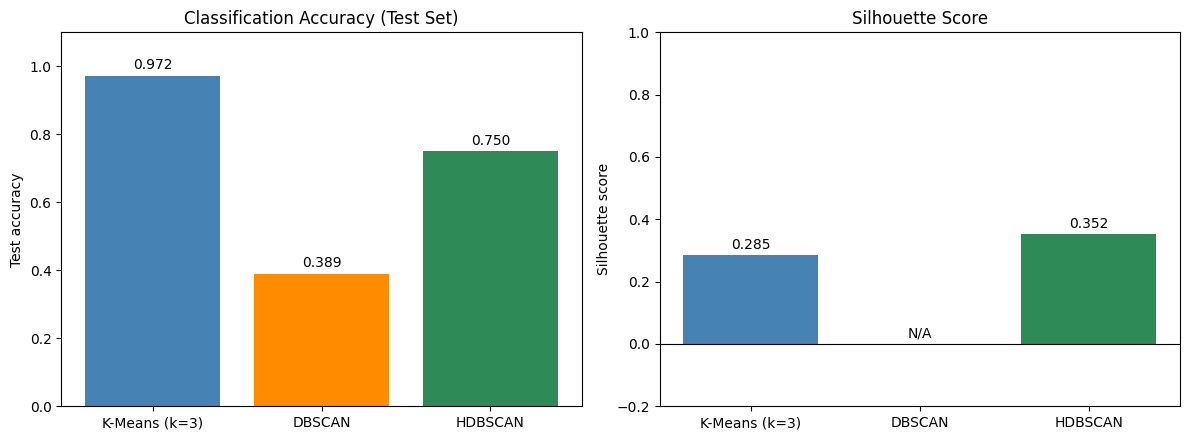

In [8]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

y = wine.target.to_numpy()

cluster_labels = {
    "K-Means (k=3)": hard_labels,
    "DBSCAN": db_labels,
    "HDBSCAN": hdb_labels,
}

idx_train, idx_test = train_test_split(
    np.arange(len(y)), test_size=0.2, stratify=y, random_state=42
)

accuracies = {}
silhouettes = {}

for name, labels in cluster_labels.items():
    labels = np.asarray(labels)

    encoder = OneHotEncoder(handle_unknown="ignore")
    F_train = encoder.fit_transform(labels[idx_train].reshape(-1, 1))
    F_test = encoder.transform(labels[idx_test].reshape(-1, 1))

    clf = LogisticRegression(max_iter=1000)
    clf.fit(F_train, y[idx_train])
    accuracies[name] = accuracy_score(y[idx_test], clf.predict(F_test))

    mask = labels != -1
    if len(np.unique(labels[mask])) >= 2:
        silhouettes[name] = silhouette_score(X_scaled[mask], labels[mask])
    else:
        silhouettes[name] = np.nan

results = pd.DataFrame({"Test accuracy": accuracies, "Silhouette score": silhouettes})
print("Results:")
display(results.round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
colors = ["steelblue", "darkorange", "seagreen"]
titles = ["Classification Accuracy (Test Set)", "Silhouette Score"]

for ax, column, title in zip(axes, results.columns, titles):
    values = results[column].to_numpy()
    bars = ax.bar(results.index, values, color=colors)
    for bar, value in zip(bars, values):
        text = "N/A" if np.isnan(value) else f"{value:.3f}"
        height = 0 if np.isnan(value) else value
        ax.text(bar.get_x() + bar.get_width() / 2, height + 0.02, text, ha="center")
    ax.set_title(title)
    ax.set_ylabel(column)

axes[0].set_ylim(0, 1.1)
axes[1].set_ylim(-0.2, 1)
axes[1].axhline(0, color="black", linewidth=0.8)

plt.tight_layout()
plt.show()